# Mega SBO Comparison: 3 Strategies x 5 Surrogate Models

This notebook will run **5 different Machine Learning models**, each executed with **3 search strategies** (*One-Shot*, *Smart Batch*, and *Iterative*).

**What will be visualized:**
1. **Performance Curve (Learning Curve):** Comparison of the maximum speed discovery rate for all five models in each strategy.
2. **Feature Location Accuracy:** A bar chart comparing the exact locations of the 5-features found by each model against the original True Global Optimum features.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances
from scipy.stats import norm
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

### 1. Data Preparation (Initial 50 DoE)

In [2]:
# --- Load Data ---
try:
    df = pd.read_csv('data_kecepatan.csv')
    if len(df.columns) == 1 or df.isnull().values.any():
         df = pd.read_csv('data_kecepatan.csv', sep=';')
    for col in df.columns:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '.'), errors='coerce')
    df = df.dropna()
except Exception as e:
    np.random.seed(42)
    X_dummy = np.random.rand(1000, 5)
    y_dummy = np.sin(X_dummy[:, 0]*5)*5 + np.cos(X_dummy[:, 1]*5)*2 + X_dummy[:, 2]*3 - (X_dummy[:, 3]-0.5)**2*10 + X_dummy[:, 4] + np.random.randn(1000) * 0.1
    df = pd.DataFrame(X_dummy, columns=[f'Feature_{i+1}' for i in range(5)])
    df['Speed'] = y_dummy

X = df.iloc[:, :5].values
y = df.iloc[:, -1].values

true_opt_y = np.max(y)
true_opt_idx = np.argmax(y)
true_opt_x = X[true_opt_idx]

# --- Data Split (Initial 50 DoE) ---
np.random.seed(42)
indices = np.random.permutation(len(X))
n_initial = 50

X_train_base = X[indices[:n_initial]].copy()
y_train_base = y[indices[:n_initial]].copy()
X_pool_base = X[indices[n_initial:]].copy()
y_pool_base = y[indices[n_initial:]].copy()

max_initial_idx = np.argmax(y_train_base)
max_initial_y = y_train_base[max_initial_idx]
max_initial_x = X_train_base[max_initial_idx]

print(f"Target True Global Optimum : {true_opt_y:.4f}")
print(f"Current Max (50 DoE)       : {max_initial_y:.4f}\n")

Target True Global Optimum : 9.7788
Current Max (50 DoE)       : 8.3382



### 2. Model Definition & Uncertainty Function (*Uncertainty Proxy*)
Since not all models have probabilistic features, we use spatial distance to the nearest data point as an *Uncertainty* proxy for SVR, MLP, and GBR.

In [3]:
def get_models():
    return {
        'GPR': GaussianProcessRegressor(kernel=1.0 * Matern(length_scale=1.0, nu=2.5), n_restarts_optimizer=5, random_state=42),
        'RF': RandomForestRegressor(n_estimators=50, random_state=42),
        'SVR': SVR(kernel='rbf', C=10, gamma='scale'),
        'MLP': MLPRegressor(hidden_layer_sizes=(50, 50), max_iter=400, random_state=42),
        'GBR': GradientBoostingRegressor(n_estimators=50, random_state=42)
    }

def get_mu_std(model, model_name, X_train, X_pool):
    if model_name == 'GPR':
        mu, std = model.predict(X_pool, return_std=True)
    elif model_name == 'RF':
        preds = np.array([tree.predict(X_pool) for tree in model.estimators_])
        mu = preds.mean(axis=0)
        std = preds.std(axis=0)
    else:
        mu = model.predict(X_pool)
        dist = pairwise_distances(X_pool, X_train)
        min_dist = dist.min(axis=1)
        std = (min_dist - min_dist.min()) / (min_dist.max() - min_dist.min() + 1e-9)
        std = std * (np.std(mu) + 1e-9)
    return mu, std

### 3. Strategy 1 Execution: One-Shot (Top 10 simultaneously)

In [4]:
res_perf_oneshot = {}
res_feat_oneshot = {}

for m_name, model in get_models().items():
    scaler = StandardScaler()
    X_t = scaler.fit_transform(X_train_base)
    X_p = scaler.transform(X_pool_base)

    model.fit(X_t, y_train_base)
    mu, _ = get_mu_std(model, m_name, X_t, X_p)

    top10_idx = np.argsort(mu)[::-1][:10]
    actual_y = y_pool_base[top10_idx]
    actual_x = X_pool_base[top10_idx]

    best_so_far = [max_initial_y]
    cur_max_y = max_initial_y
    cur_best_x = max_initial_x

    for i, val in enumerate(actual_y):
        if val > cur_max_y:
            cur_max_y = val
            cur_best_x = actual_x[i]
        best_so_far.append(cur_max_y)

    res_perf_oneshot[m_name] = best_so_far
    res_feat_oneshot[m_name] = cur_best_x
print("One-Shot Strategy Completed")

One-Shot Strategy Completed


### 4. Strategy 2 Execution: Smart Batch (5 Top Mean + 5 Top Uncertainty)

In [5]:
res_perf_batch = {}
res_feat_batch = {}

for m_name, model in get_models().items():
    scaler = StandardScaler()
    X_t = scaler.fit_transform(X_train_base)
    X_p = scaler.transform(X_pool_base)

    model.fit(X_t, y_train_base)
    mu, std = get_mu_std(model, m_name, X_t, X_p)

    exploit_idx = np.argsort(mu)[::-1][:5]
    explore_idx_cands = np.argsort(std)[::-1]
    explore_idx = [idx for idx in explore_idx_cands if idx not in exploit_idx][:5]

    top10_idx = np.concatenate([exploit_idx, explore_idx])
    actual_y = y_pool_base[top10_idx]
    actual_x = X_pool_base[top10_idx]

    best_so_far = [max_initial_y]
    cur_max_y = max_initial_y
    cur_best_x = max_initial_x

    for i, val in enumerate(actual_y):
        if val > cur_max_y:
            cur_max_y = val
            cur_best_x = actual_x[i]
        best_so_far.append(cur_max_y)

    res_perf_batch[m_name] = best_so_far
    res_feat_batch[m_name] = cur_best_x
print("Smart Batch Strategy Completed")

Smart Batch Strategy Completed


### 5. Strategy 3 Execution: Iterative (10x Active Learning Loop)

In [6]:
res_perf_iter = {}
res_feat_iter = {}

def expected_improvement(mu, sigma, current_opt, xi=0.01):
    with np.errstate(divide='warn'):
        imp = mu - current_opt - xi
        Z = imp / sigma
        ei = imp * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei

for m_name in get_models().keys():
    X_train_iter = X_train_base.copy()
    y_train_iter = y_train_base.copy()
    X_pool_iter = X_pool_base.copy()
    y_pool_iter = y_pool_base.copy()

    best_so_far = [max_initial_y]

    for i in range(10):
        scaler = StandardScaler()
        X_t_scaled = scaler.fit_transform(X_train_iter)
        X_p_scaled = scaler.transform(X_pool_iter)

        model = get_models()[m_name]
        model.fit(X_t_scaled, y_train_iter)

        mu, std = get_mu_std(model, m_name, X_t_scaled, X_p_scaled)
        current_opt = np.max(y_train_iter)

        ei = expected_improvement(mu, std, current_opt)
        best_idx = np.argmax(ei)

        actual_y = y_pool_iter[best_idx]
        actual_x = X_pool_iter[best_idx]

        X_train_iter = np.vstack([X_train_iter, actual_x])
        y_train_iter = np.append(y_train_iter, actual_y)

        X_pool_iter = np.delete(X_pool_iter, best_idx, axis=0)
        y_pool_iter = np.delete(y_pool_iter, best_idx, axis=0)

        best_so_far.append(np.max(y_train_iter))

    res_perf_iter[m_name] = best_so_far

    # Find the overall best X
    best_idx_overall = np.argmax(y_train_iter)
    res_feat_iter[m_name] = X_train_iter[best_idx_overall]
print("Iterative Strategy Completed")

Iterative Strategy Completed


### 6. Visualization 1: Performance Curve (Learning Curve) per Strategy

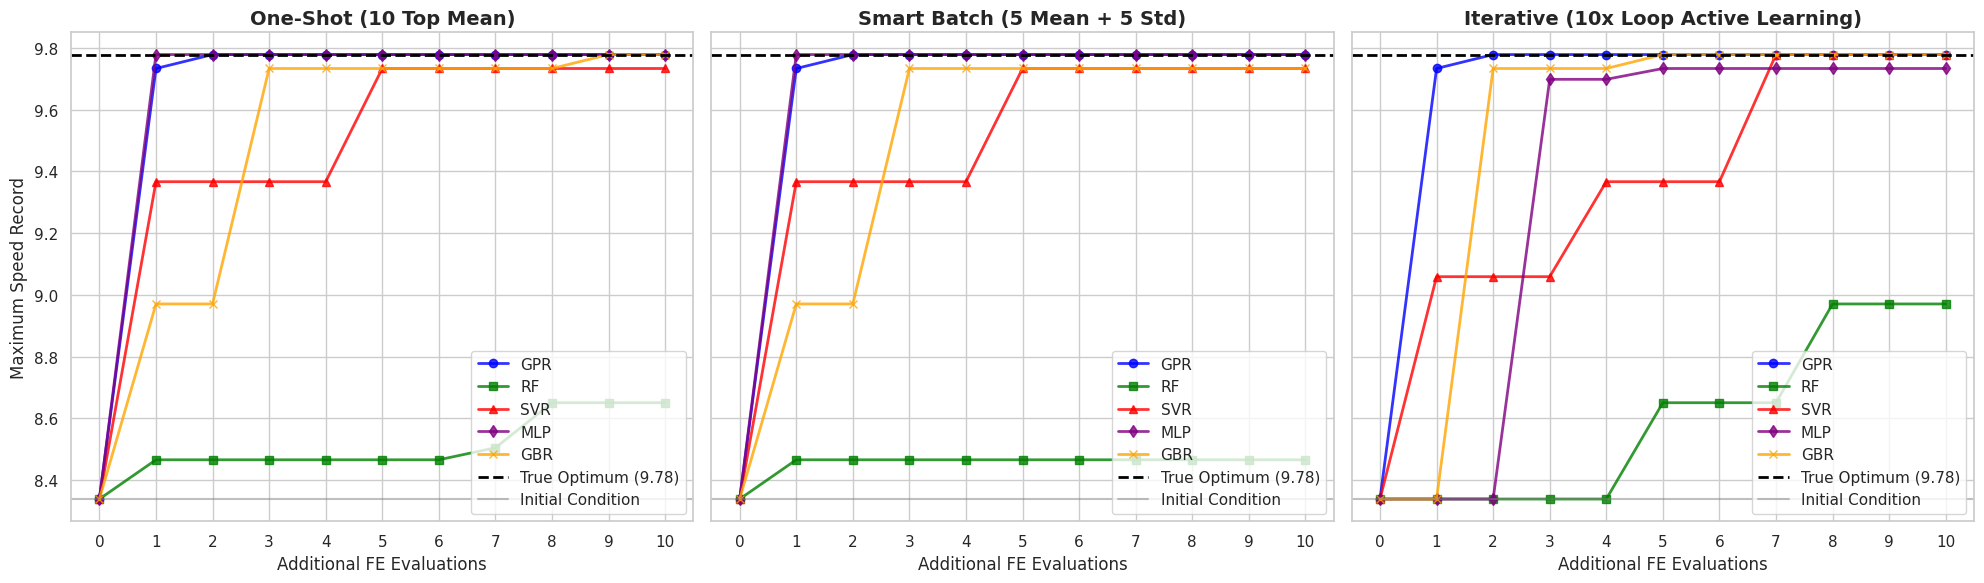

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
x_evals = np.arange(11)
colors = {'GPR': 'blue', 'RF': 'green', 'SVR': 'red', 'MLP': 'purple', 'GBR': 'orange'}
markers = {'GPR': 'o', 'RF': 's', 'SVR': '^', 'MLP': 'd', 'GBR': 'x'}

strats_perf = [
    ('One-Shot (10 Top Mean)', res_perf_oneshot),
    ('Smart Batch (5 Mean + 5 Std)', res_perf_batch),
    ('Iterative (10x Loop Active Learning)', res_perf_iter)
]

for i, (title, results_dict) in enumerate(strats_perf):
    ax = axes[i]
    for m_name, perf in results_dict.items():
        ax.plot(x_evals, perf, marker=markers[m_name], color=colors[m_name], label=m_name, linewidth=2, alpha=0.8)

    ax.axhline(true_opt_y, color='black', linestyle='--', linewidth=2, label=f'True Optimum ({true_opt_y:.2f})')
    ax.axhline(max_initial_y, color='gray', linestyle='-', alpha=0.5, label='Initial Condition')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Additional FE Evaluations', fontsize=12)
    ax.set_xticks(x_evals)
    if i == 0: ax.set_ylabel('Maximum Speed Record', fontsize=12)
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

### 7. Visualization 2: Feature Location Accuracy per Strategy
How close the feature combination points found by the models are compared to the *True Optimum* (Green Line).

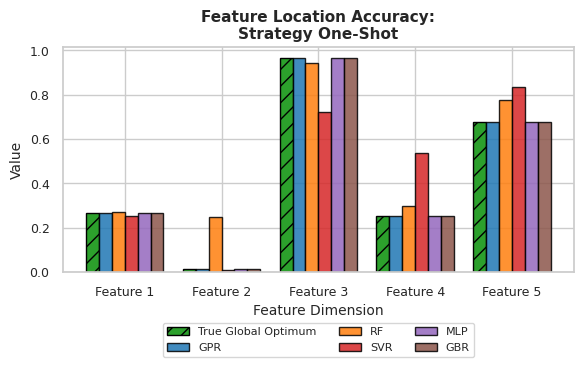

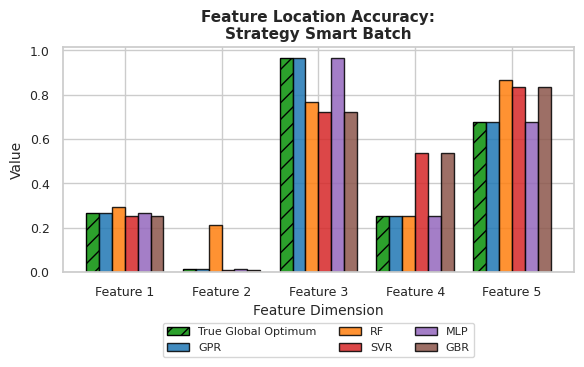

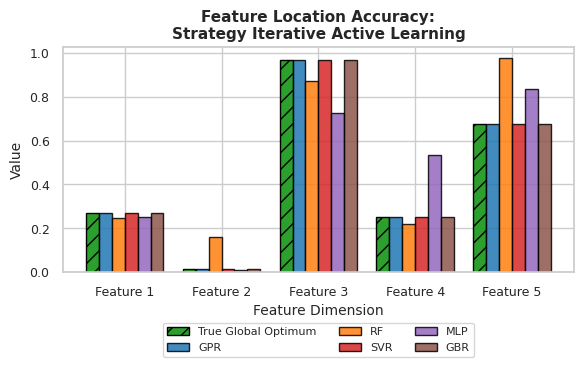

In [9]:
def plot_feature_comparison_5models(true_x, dict_found_x, strategy_name):
    # Mengubah figsize menjadi rasio 3:2 (atau setara 2:3 pada proporsi panjang:lebar)
    # Ukuran (6, 4) sangat ideal untuk masuk ke dalam 1 kolom paper IEEE
    plt.figure(figsize=(6, 4))
    x_pos = np.arange(len(true_x))
    models = list(dict_found_x.keys())
    n_models = len(models)
    total_width = 0.8
    width = total_width / (n_models + 1)

    plt.bar(x_pos - total_width/2 + width/2, true_x, width, label='True Global Optimum', color='#2ca02c', edgecolor='black', hatch='//')

    colors_bar = ['#1f77b4', '#ff7f0e', '#d62728', '#9467bd', '#8c564b']
    for i, m in enumerate(models):
        offset = x_pos - total_width/2 + width/2 + (i+1)*width
        plt.bar(offset, dict_found_x[m], width, label=m, color=colors_bar[i], alpha=0.85, edgecolor='black')

    # Ukuran font disesuaikan agar proporsional dengan figur yang lebih kecil
    plt.title(f'Feature Location Accuracy:\nStrategy {strategy_name}', fontsize=11, fontweight='bold')
    plt.xlabel('Feature Dimension', fontsize=10)
    plt.ylabel('Value', fontsize=10)
    plt.xticks(x_pos, [f'Feature {i+1}' for i in range(len(true_x))], fontsize=9)
    plt.yticks(fontsize=9)

    # Legend diubah menjadi ncol=3 (2 baris) agar tidak terpotong di lebar yang lebih kecil
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)

    plt.tight_layout()
    plt.show()

# Plot for each strategy
plot_feature_comparison_5models(true_opt_x, res_feat_oneshot, "One-Shot")
plot_feature_comparison_5models(true_opt_x, res_feat_batch, "Smart Batch")
plot_feature_comparison_5models(true_opt_x, res_feat_iter, "Iterative Active Learning")